# Расчеты

In [1]:
import random
import numpy as np

# Физические параметры системы(СИ)
mu_water = 1e-3 #Па * с при 20.5 по цельсию

#Разница давлений

class Pore_body:
    def __init__(self, size = None, G = None, pressure = None, pressure_is_fixed = False): #считаем пору кубом
        # self.position = position
        self.size = size
        self.pressure = pressure
        self.pressure_is_fixed = pressure_is_fixed
        self.g = float('inf')
        self.R = None
    # def get_g(self):
    #     if self.g != None:
    #         return self.g
    #     A = self.size ** 2
    #     P = 4 * self.size
    #     self.g = 0.5623 * A ** 3 / ((P ** 2 * mu_water) * (self.size / 2))
    #     return self.g
    def set_pressure(self, pressure):
        self.pressure = pressure
        self.pressure_is_fixed = True

class Pore_throat:
    def __init__(self, g = None, pb = None):
        self.pb = pb #пара пор (min, max), которые соединяет трот
        self.g = g
        self.R = None
        self.G = None
        self.L = None
        self.g_true = None
    
class PN_simple: #некруглые поры и каналы - готовы конкретных форм
    def __init__(self, connection_dict, pb_dict: Pore_body, pt_dict: Pore_throat):
        self.connection_dict = connection_dict
        self.pb_dict = pb_dict
        self.pt_dict = pt_dict #ключ - id трота
        
        #между парой пор может быть несколько тротов - они соединены параллельно, проводимости складываются
        self.pair_g = {}
        for pt in self.pt_dict.values():
            self.pair_g[pt.pb] = self.pair_g.get(pt.pb, 0) + pt.g_true
                
    def gen_pb_and_pt_r(self):
        #единицы в физические, размеры в метрах, все остальное тоже в метрическую систему чтобы можно было решать в си - готово

        for i in self.connection_dict.keys():
            self.pb_dict[i].size = random.normalvariate(pore_body_size_mean, pore_body_size_sigma)
        for i in self.connection_dict.keys():
            for j in self.connection_dict[i]:
                self.pt_dict[(min(i, j), max(i, j))].params = [random.normalvariate(pore_throat_size_mean, pore_throat_size_sigma) for _ in range(3)]
                self.pt_dict[(min(i, j), max(i, j))].shape = random.randint(1, 3)

    def get_g(self, pb_1, pb_2):
        # return 1 / (1 / self.pb_dict[pb_1].get_g() + 1 / self.pb_dict[pb_2].get_g() + 1 / self.pt_dict[(min(pb_1, pb_2), max(pb_1, pb_2))].get_g())
        return self.pair_g[tuple(sorted([pb_1, pb_2]))]

    def solve_for_p(self):
        var = sorted([i for i in self.connection_dict.keys() if not self.pb_dict[i].pressure_is_fixed])

        pb_num = {}
        for i in range(len(var)):
            pb_num[var[i]] = i

        p_matrix_a = np.zeros((len(var), len(var)))
        p_matrix_b = np.zeros(len(var))
        for i in self.connection_dict.keys():
            if self.pb_dict[i].pressure_is_fixed: #skip if p is fixed
                continue
            a = [0 for _ in range(len(var))]
            b = 0
            for j in self.connection_dict[i]:
                g = self.get_g(i, j)
                if self.pb_dict[j].pressure_is_fixed:
                    b += g * self.pb_dict[j].pressure #gP_1 - gP_2 + g_2*P_1 - g_2 * P_3 .... = 0
                else:
                    a[pb_num[j]] -= g
                a[pb_num[i]] += g
            # print(a)
            # print(b)
            p_matrix_a[pb_num[i], :] = a
            p_matrix_b[pb_num[i]] = b

        print('start solving matrix')
        x = np.linalg.solve(p_matrix_a, p_matrix_b)

        for i in range(len(var)):
            self.pb_dict[var[i]].pressure = x[i]
    
    def get_flow(self):
        res = {}
        for i, pt in self.pt_dict.items():
            if pt.pb[0] not in self.connection_dict or pt.pb[1] not in self.connection_dict: #изолированные поры не решались
                continue
            res[i] = pt.g_true * abs(self.pb_dict[pt.pb[0]].pressure - self.pb_dict[pt.pb[1]].pressure)
        return res
    
    def side_flow(self, side):
        res = 0
        for i in side:
            for j in self.connection_dict[i]:
                res += self.get_g(i, j) * abs(self.pb_dict[i].pressure - self.pb_dict[j].pressure)
        return res
       
    def remove_throat(self, pb_1, pb_2):
        self.connection_dict[pb_1].remove(pb_2)
        self.connection_dict[pb_2].remove(pb_1)
    
    def get_pressure(self):
        res = {}
        for i in self.connection_dict.keys():
            res[i] = self.pb_dict[i].pressure
        return res

# Парсим сеть

## Выбираем сеть

In [2]:
import os
print('Choose PN files dir')

dirs = next(os.walk('data/'))[1]
for i in range(len(dirs)):
    print(f'{i + 1}: {dirs[i]}')

Choose PN files dir
1: 2
2: 3
3: 1


In [3]:
target = 'data/' + dirs[int(input()) - 1] + '/'

In [4]:
pn_alpha = 0 

In [5]:
import re

files = next(os.walk(target))[2]

pn_files = [0 for i in range(4)]
for f in files:
    if re.findall('node1.dat', f):
        pn_files[0] = target + f
    elif re.findall('node2.dat', f):
        pn_files[1] = target + f
    elif re.findall('link1.dat', f):
        pn_files[2] = target + f
    elif re.findall('link2.dat', f):
        pn_files[3] = target + f
print(pn_files)

['data/3/input_node1.dat', 'data/3/input_node2.dat', 'data/3/input_link1.dat', 'data/3/input_link2.dat']


In [6]:
border1 = -7
border2 = -6

In [7]:
connection_dict = {} #добавить обрубание связи - готово
pb_dict = {}
pt_dict = {}

Отдельно обрабатываем пору border1 и пору border2 - служебные поры, которые указывают на края образца

In [8]:
connection_dict[border1] = []
connection_dict[border2] = []
pb_dict[border1] = Pore_body()
pb_dict[border2] = Pore_body()
pb_dict[border1].R = float('inf')
pb_dict[border2].R = float('inf')

читаем по очереди файлы

In [9]:
with open(pn_files[0], 'r') as fi:
    lines = fi.readlines()
    for linenum in range(1, len(lines)):
        line = lines[linenum].split()
        connection_dict[int(line[0])] = []
        for i in range(5, 5 + int(line[4])):
            if int(line[i]) in connection_dict[int(line[0])]: #параллельные троты, уже учтены через pair_g
                continue
            if int(line[i]) > 0:
                connection_dict[int(line[0])].append(int(line[i]))
            if int(line[i]) == border2 or int(line[i]) == border1:
                connection_dict[int(line[0])].append(int(line[i]))
                connection_dict[int(line[i])].append(int(line[0]))
        # print(line[0], 5 + int(line[4]), line[7 + int(line[4])], line)
        # if int(line[5 + int(line[4])]) == 1:
        #     pb_dict[int(line[0])].set_pressure(100000)
        #     print(1111)
        # if int(line[6 + int(line[4])]) == 1:
        #     pb_dict[int(line[0])].set_pressure(0)
        #     print(222)

Код на с++ для определения формыы канала
```
private:
    template<class ElementType>
    [[nodiscard]] FlowElementPtr build(
        ElementType&& element_info,
        const std::shared_ptr<SimulationContext>& simulation_ctx) const {
        const auto shape_factor = element_info.shapeFactor();
        if (shape_factor <= sqrt(3.0) / 36.0) {  // NOLINT
            const TriangleFlowElementFactory factory;
            return factory(std::forward<ElementType>(element_info),
                           simulation_ctx);
        }
        if (shape_factor < 0.07) {  // NOLINT
            const SquareFlowElementFactory factory;
            return factory(std::forward<ElementType>(element_info),
                           simulation_ctx);
        }
        const CircleFlowElementFactory factory;
        return factory(std::forward<ElementType>(element_info), simulation_ctx);
    }
};
```

## Код на плюсах из программы

# Тут параллельно считываем файл и расcчитываем гидравлические сопротивления

In [10]:
def elemtype(G): #1 - triangle, 2 - square, 3 - circle
    if G <= 3 ** 0.5 / 36:
        return 1
    if G < 0.7:
        return 2
    return 3

In [11]:
with open(pn_files[1], 'r') as fi:
    lines = fi.readlines()
    for linenum in range(0, len(lines)):
        line = lines[linenum].split()
        pb_dict[int(line[0])] = Pore_body()

        throat_shape = elemtype(float(line[3]))
        if throat_shape == 1:
            pb_dict[int(line[0])].g = 0.6 * (float(line[2]) ** 4 / (16 * float(line[3]))) 
        elif throat_shape == 2:
            pb_dict[int(line[0])].g = 0.5623 * (float(line[2]) ** 4 / (16 * float(line[3]))) 
        elif throat_shape == 3:
            pb_dict[int(line[0])].g = 0.5 * (float(line[2]) ** 4 / (16 * float(line[3])))
        else:
            raise Exception('wrong throat shape')
        # pb_dict[int(line[0])].g = 0.5 * (float(line[2]) ** 4) / (16 * float(line[3]))
        
        pb_dict[int(line[0])].R = float(line[2])

Формула расчета абсолютной проводимости зависит от формы элемента:

- Для круглого элемента: $ 0.5 * \frac{r^4}{16G} $, где $ r $ — радиус, а $ G $ — фактор формы элемента;
- Для квадратного элемента: $ 0.5623 * \frac{r^4}{16G} $, где $ r $ — радиус, а $ G $ — фактор формы элемента;
- Для треугольного элемента: $ 0.6 * \frac{r^4}{16G} $, где $ r $ — радиус, а $ G $ — фактор формы элемента;
- Для прямоугольного элемента: $ 16 \frac{r^4}{12} \frac{m}{\pi^2 \sum_{n=1}^\infty \frac{1}{(2n-1)^2} \frac{\cosh((2n-1)m)-1}{\sinh((2n-1)m)}} $, где $ r $ — радиус, $ m $ — отношение большей стороны прямоугольника к меньшей.

In [12]:
with open(pn_files[2], 'r') as fi:
    lines = fi.readlines()
    for linenum in range(1, len(lines)):
        line = lines[linenum].split()
        if int(line[1]) < 0 and int(line[1]) != border1 and int(line[1]) != border2:
            continue
        if int(line[2]) < 0 and int(line[2]) != border1 and int(line[2]) != border2:
            continue
        throatid = int(line[0])
        pt_dict[throatid] = Pore_throat(pb = tuple(sorted([int(line[1]), int(line[2])])))

        throat_shape = elemtype(float(line[4]))
        if throat_shape == 1:
            pt_dict[throatid].g = 0.6 * (float(line[3]) ** 4 / (16 * float(line[4])))
        elif throat_shape == 2:
            pt_dict[throatid].g = 0.5623 * (float(line[3]) ** 4 / (16 * float(line[4])))
        elif throat_shape == 3:
            pt_dict[throatid].g = 0.5 * (float(line[3]) ** 4 / (16 * float(line[4])))
        else:
            raise Exception('wrong throat shape')
        

        # pt_dict[throatid].g = 0.5 * (float(line[3]) ** 4) / (16 * float(line[4]))
        
        pt_dict[throatid].L = float(line[5])
        pt_dict[throatid].R = float(line[3])


In [13]:
with open(pn_files[3], 'r') as fi:
    lines = fi.readlines()
    for linenum in range(0, len(lines)):
        line = lines[linenum].split()
        if int(line[1]) < 0 and int(line[1]) != border1 and int(line[1]) != border2:
            continue
        if int(line[2]) < 0 and int(line[2]) != border1 and int(line[2]) != border2:
            continue
        throatid = int(line[0])
        L_1 = float(line[3]) * (1 - pn_alpha * (pt_dict[throatid].R / pb_dict[int(line[1])].R))
        L_2 = float(line[4]) * (1 - pn_alpha * (pt_dict[throatid].R / pb_dict[int(line[2])].R))
        pt_dict[throatid].g_true = ((L_1 / pb_dict[int(line[1])].g) + (L_2 / pb_dict[int(line[2])].g) + (float(line[5]) / pt_dict[throatid].g)) ** -1
        

Проводимость одного канала (половина поры 1 + трот + половина поры 2, соединены последовательно):

$$ g_k = \left( \frac{L_{1,k}}{g_{p1}} + \frac{L_{t,k}}{g_{t,k}} + \frac{L_{2,k}}{g_{p2}} \right)^{-1} $$

Две поры могут быть соединены несколькими тротами. Перепад давления на них одинаковый, поэтому они соединены параллельно и проводимость пары пор равна сумме:

$$ g_{ij} = \sum_{k \in T(i,j)} g_k $$

Суммирование делается в `PN_simple.pair_g`, в уравнениях баланса каждая пара соседей учитывается один раз.

Тут избавимся от изолированных пор

In [14]:
connection_dict_new = {}

In [15]:
def mark_neighbours(node):
    connection_dict_new[node] = []
    for neighbour in connection_dict[node]:
        if neighbour in connection_dict.keys():
            connection_dict_new[node].append(neighbour)
            if neighbour not in connection_dict_new:
                mark_neighbours(neighbour)

In [16]:
import sys
sys.setrecursionlimit(10**6)
mark_neighbours(border1)

Теперь производим расчеты

In [17]:
pb_dict[border1].set_pressure(1000)
pb_dict[border2].set_pressure(0)

In [18]:
PN = PN_simple(connection_dict_new, pb_dict, pt_dict)
PN.solve_for_p()

start solving matrix


Рассчитаем коэффициент проницаемости

In [19]:
with open(pn_files[0], 'r') as fi:
    lines = fi.readlines()
    line = lines[0].split()
    Lx, Ly, Lz = float(line[1]), float(line[2]), float(line[3])
    print(Lx, Ly, Lz)

0.0003 0.0003 0.0003


In [20]:
Q = PN.side_flow([border1])
print(Q)

K = Q*Lx/(Ly * Lz * abs(pb_dict[border1].pressure - pb_dict[border2].pressure))
print(f'Проницаемость {K:.3e} м^2 = {K * 1e15:.1f} мДарси')

9.114926027740393e-13
Проницаемость 3.038e-12 м^2 = 3038.3 мДарси


# Визуализируем полученное решение

In [49]:
coords_dict = {}
with open(pn_files[0], 'r') as fi:
    lines = fi.readlines()
    for linenum in range(1, len(lines)):
        line = lines[linenum].split()
        coords_dict[int(line[0])] = (float(line[1]), float(line[2]), float(line[3]))

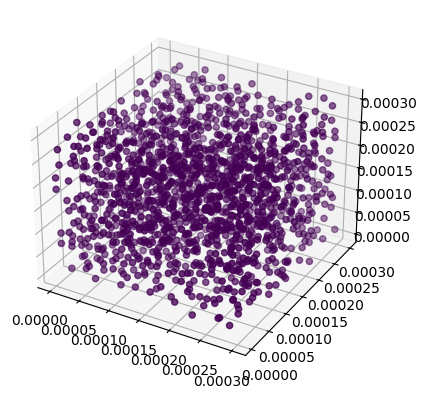

In [50]:
import matplotlib
from matplotlib import pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

x = [coords_dict[i][0] for i in connection_dict.keys() if i > 0]
y = [coords_dict[i][1] for i in connection_dict.keys() if i > 0]
z = [coords_dict[i][2] for i in connection_dict.keys() if i > 0]

c = []
for i in connection_dict:
    if i < 0:
        continue
    # if i not in connection_dict_new:
    #     c.append(1)
    if -5 in connection_dict[i]:
        c.append(1)
        print(coords_dict[i])
    else:
        c.append(0)

ax.scatter(x, y, z, c=c,)

In [51]:
radius_dict = {}
with open(pn_files[1], 'r') as fi:
    lines = fi.readlines()
    for linenum in range(0, len(lines)):
        line = lines[linenum].split()
        radius_dict[int(line[0])] = float(line[2])

In [52]:
p = PN.get_pressure()
p.pop(border1)
p.pop(border2)

0

In [53]:
size = [radius_dict[i] * 5e6 for i in p.keys()]

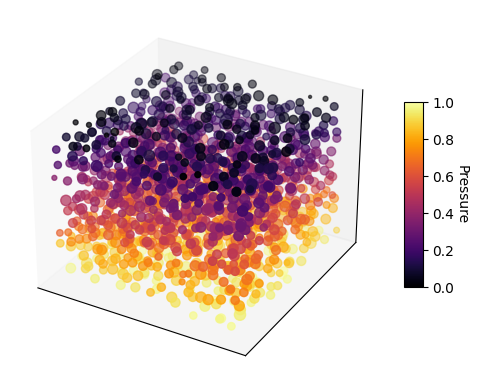

In [54]:
# смотреть лучше в фале interactive.py
import matplotlib
from matplotlib import pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

x = [coords_dict[i][0] for i in p.keys()]
y = [coords_dict[i][1] for i in p.keys()]
z = [coords_dict[i][2] for i in p.keys()]

pmax, pmin = max(list(p.values())), min(list(p.values()))

colors = [(p[i] - pmin) / pmax for i in p.keys()] # первый параметр до 0.9 чтобы было красиво

# Создание scatter plot и сохранение объекта
sc = ax.scatter(x, y, z, s=size, c=colors, cmap='inferno')

# Добавление цветовой шкалы
cbar = fig.colorbar(sc, ax=ax, shrink=0.5, aspect=10)
cbar.set_label('Pressure', rotation=270, labelpad=10)

ax.set_xticks([]), ax.set_yticks([]), ax.set_zticks([]) 

# Настройки отображения
# ax.set_axis_off()

plt.savefig('mypnm.png', dpi=800, bbox_inches='tight')
plt.show()